# Water points in Nakasongola and Luwero: what works, and for how long?

**KAI Academy · practice notebook 2.** Real, open data from Uganda: the Water Point Data Exchange (WPDx) records for
Nakasongola and Luwero districts, most of them reported by the Ministry of Water and Environment, published under
**CC BY 4.0** (see `DATA.md`). You will clean the status labels, compare technologies, look at age, and map
non-functional points, and you will learn why a status can be years old.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

wp = pd.read_csv("data/uganda_waterpoints_nakasongola_luwero.csv", parse_dates=["report_date"])
print(len(wp), "water points")
print(wp.source.value_counts())
wp.head()

2050 water points
source
Ministry of Water and Environment, Uganda    1575
Ugandan Water Project                         380
World Vision                                   92
Living Water International                      2
International Lifeline Fund                     1
Name: count, dtype: int64


,wpdx_id,clean_adm2,clean_adm3,lat_deg,lon_deg,water_source,water_tech_clean,_water_tech_category,facility_type,install_year,report_date,status_clean,status_id,management_clean,is_urban,source
0,6GGJH8FW+GF8,Luwero,Katikamu,0.573790,32.346210,borehole,Hand Pump - India Mark,Hand Pump,Improved,2022.0,2022-07-18,Non-Functional,Yes,Community Management,False,Ugandan Water Project
1,6GGJH8PW+75J,Luwero,Katikamu,0.585705,32.345381,borehole,Hand Pump - India Mark,Hand Pump,Improved,2021.0,2021-11-09,Non-Functional,Yes,Community Management,False,Ugandan Water Project
2,6GGJH9GF+26F,Luwero,Katikamu,0.575053,32.373062,borehole,Hand Pump - India Mark,Hand Pump,Improved,2020.0,2021-11-10,Non-Functional,Yes,Community Management,False,Ugandan Water Project
3,6GGJH9GG+585,Luwero,Katikamu,0.575376,32.375855,borehole,Hand Pump - India Mark,Hand Pump,Improved,2020.0,2021-11-10,Non-Functional,Yes,Community Management,False,Ugandan Water Project
4,6GGJH9HM+846,Luwero,Katikamu,0.578281,32.382761,borehole,Hand Pump - India Mark,Hand Pump,Improved,2021.0,2021-11-10,Non-Functional,Yes,Community Management,False,Ugandan Water Project


## 1. How old is each status?

A water point's status is only as fresh as its last visit. Before counting, look at when each was last reported.

In [2]:
wp["report_year"] = wp.report_date.dt.year
print(wp.report_year.value_counts().sort_index())
wp["functional"] = wp.status_clean.str.startswith("Functional") & ~wp.status_clean.str.contains("not in use")

report_year
2010    1526
2011      10
2012       2
2013     102
2014      27
2016      19
2017       3
2018       5
2019      20
2020       6
2021     208
2022      68
2023      54
Name: count, dtype: int64


## 2. Functionality by technology, and by reporting year

In [3]:
t = wp.groupby("water_tech_clean").functional.agg(["mean", "size"]).sort_values("size", ascending=False)
print(t.rename(columns={"mean": "share functional"}).round(2))
by_year = wp.groupby("report_year").functional.agg(["mean", "size"])
print(by_year.rename(columns={"mean": "share functional"}).round(2))

                        share functional  size
water_tech_clean                              
Hand Pump - Afridev                 0.75   791
Public Tapstand                     0.78   449
Hand Pump - India Mark              0.00   249
Motorized Pump                      0.00    84
Kiosk                               0.87    47
Hand Pump                           0.00     1
             share functional  size
report_year                        
2010                     0.74  1526
2011                     0.80    10
2012                     1.00     2
2013                     0.31   102
2014                     0.15    27
2016                     0.00    19
2017                     0.00     3
2018                     0.00     5
2019                     0.00    20
2020                     0.00     6
2021                     0.00   208
2022                     0.00    68
2023                     0.00    54


In [4]:
print(pd.crosstab([wp.source, wp.water_tech_clean], wp.functional, margins=True))

functional                                                        False  True  \
source                                    water_tech_clean                      
International Lifeline Fund               Hand Pump                   1     0   
Living Water International                Hand Pump - India Mark      2     0   
Ministry of Water and Environment, Uganda Hand Pump - Afridev       199   592   
                                          Kiosk                       6    41   
                                          Public Tapstand            98   351   
Ugandan Water Project                     Hand Pump - India Mark    246     0   
World Vision                              Hand Pump - India Mark      1     0   
                                          Motorized Pump             84     0   
All                                                                 637   984   

functional                                                         All  
source                             

The share functional depends strongly on **when** the points were surveyed and **who** surveyed them: here every
India Mark hand pump and motorised pump comes from NGO surveys that recorded all of them as non-functional, while the
Ministry records (mostly 2010) cover the Afridev pumps, tapstands and kiosks. So the technology table above says more
about who surveyed than about the pumps. Compare like with like.

## 3. Age at report

In [5]:
wp["age_at_report"] = wp.report_year - wp.install_year
a = wp[(wp.age_at_report >= 0) & (wp.age_at_report <= 50)]
bins = pd.cut(a.age_at_report, [0, 2, 5, 10, 20, 50], include_lowest=True)
print(a.functional.groupby(bins, observed=True).agg(["mean", "size"]).rename(columns={"mean": "share functional"}).round(2))

               share functional  size
age_at_report                        
(-0.001, 2.0]              0.22   618
(2.0, 5.0]                 0.69   179
(5.0, 10.0]                0.72   619
(10.0, 20.0]               0.79   261
(20.0, 50.0]               0.70   241


## 4. Map

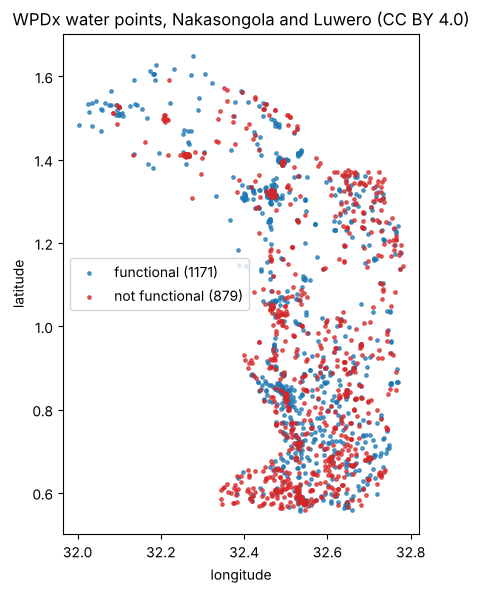

In [6]:
fig, ax = plt.subplots(figsize=(6.5, 6.5))
for f, c, lab in [(True, "tab:blue", "functional"), (False, "tab:red", "not functional")]:
    s = wp[wp.functional == f]
    ax.scatter(s.lon_deg, s.lat_deg, s=6, c=c, label=f"{lab} ({len(s)})", alpha=0.7)
ax.set_aspect("equal"); ax.legend(); ax.set_xlabel("longitude"); ax.set_ylabel("latitude")
ax.set_title("WPDx water points, Nakasongola and Luwero (CC BY 4.0)"); plt.show()

**Your turn.** (1) Which sub-county (`clean_adm3`) has the most non-functional hand pumps reported since 2020?
(2) Repeat section 2 using only Ministry records, then only the others. (3) What would you need to know before using
this map to plan repairs?

*Data: Water Point Data Exchange (WPDx), records as published for Uganda, mainly from the Ministry of Water and
Environment, Uganda; licensed CC BY 4.0. Extract of 1 November 2026.*